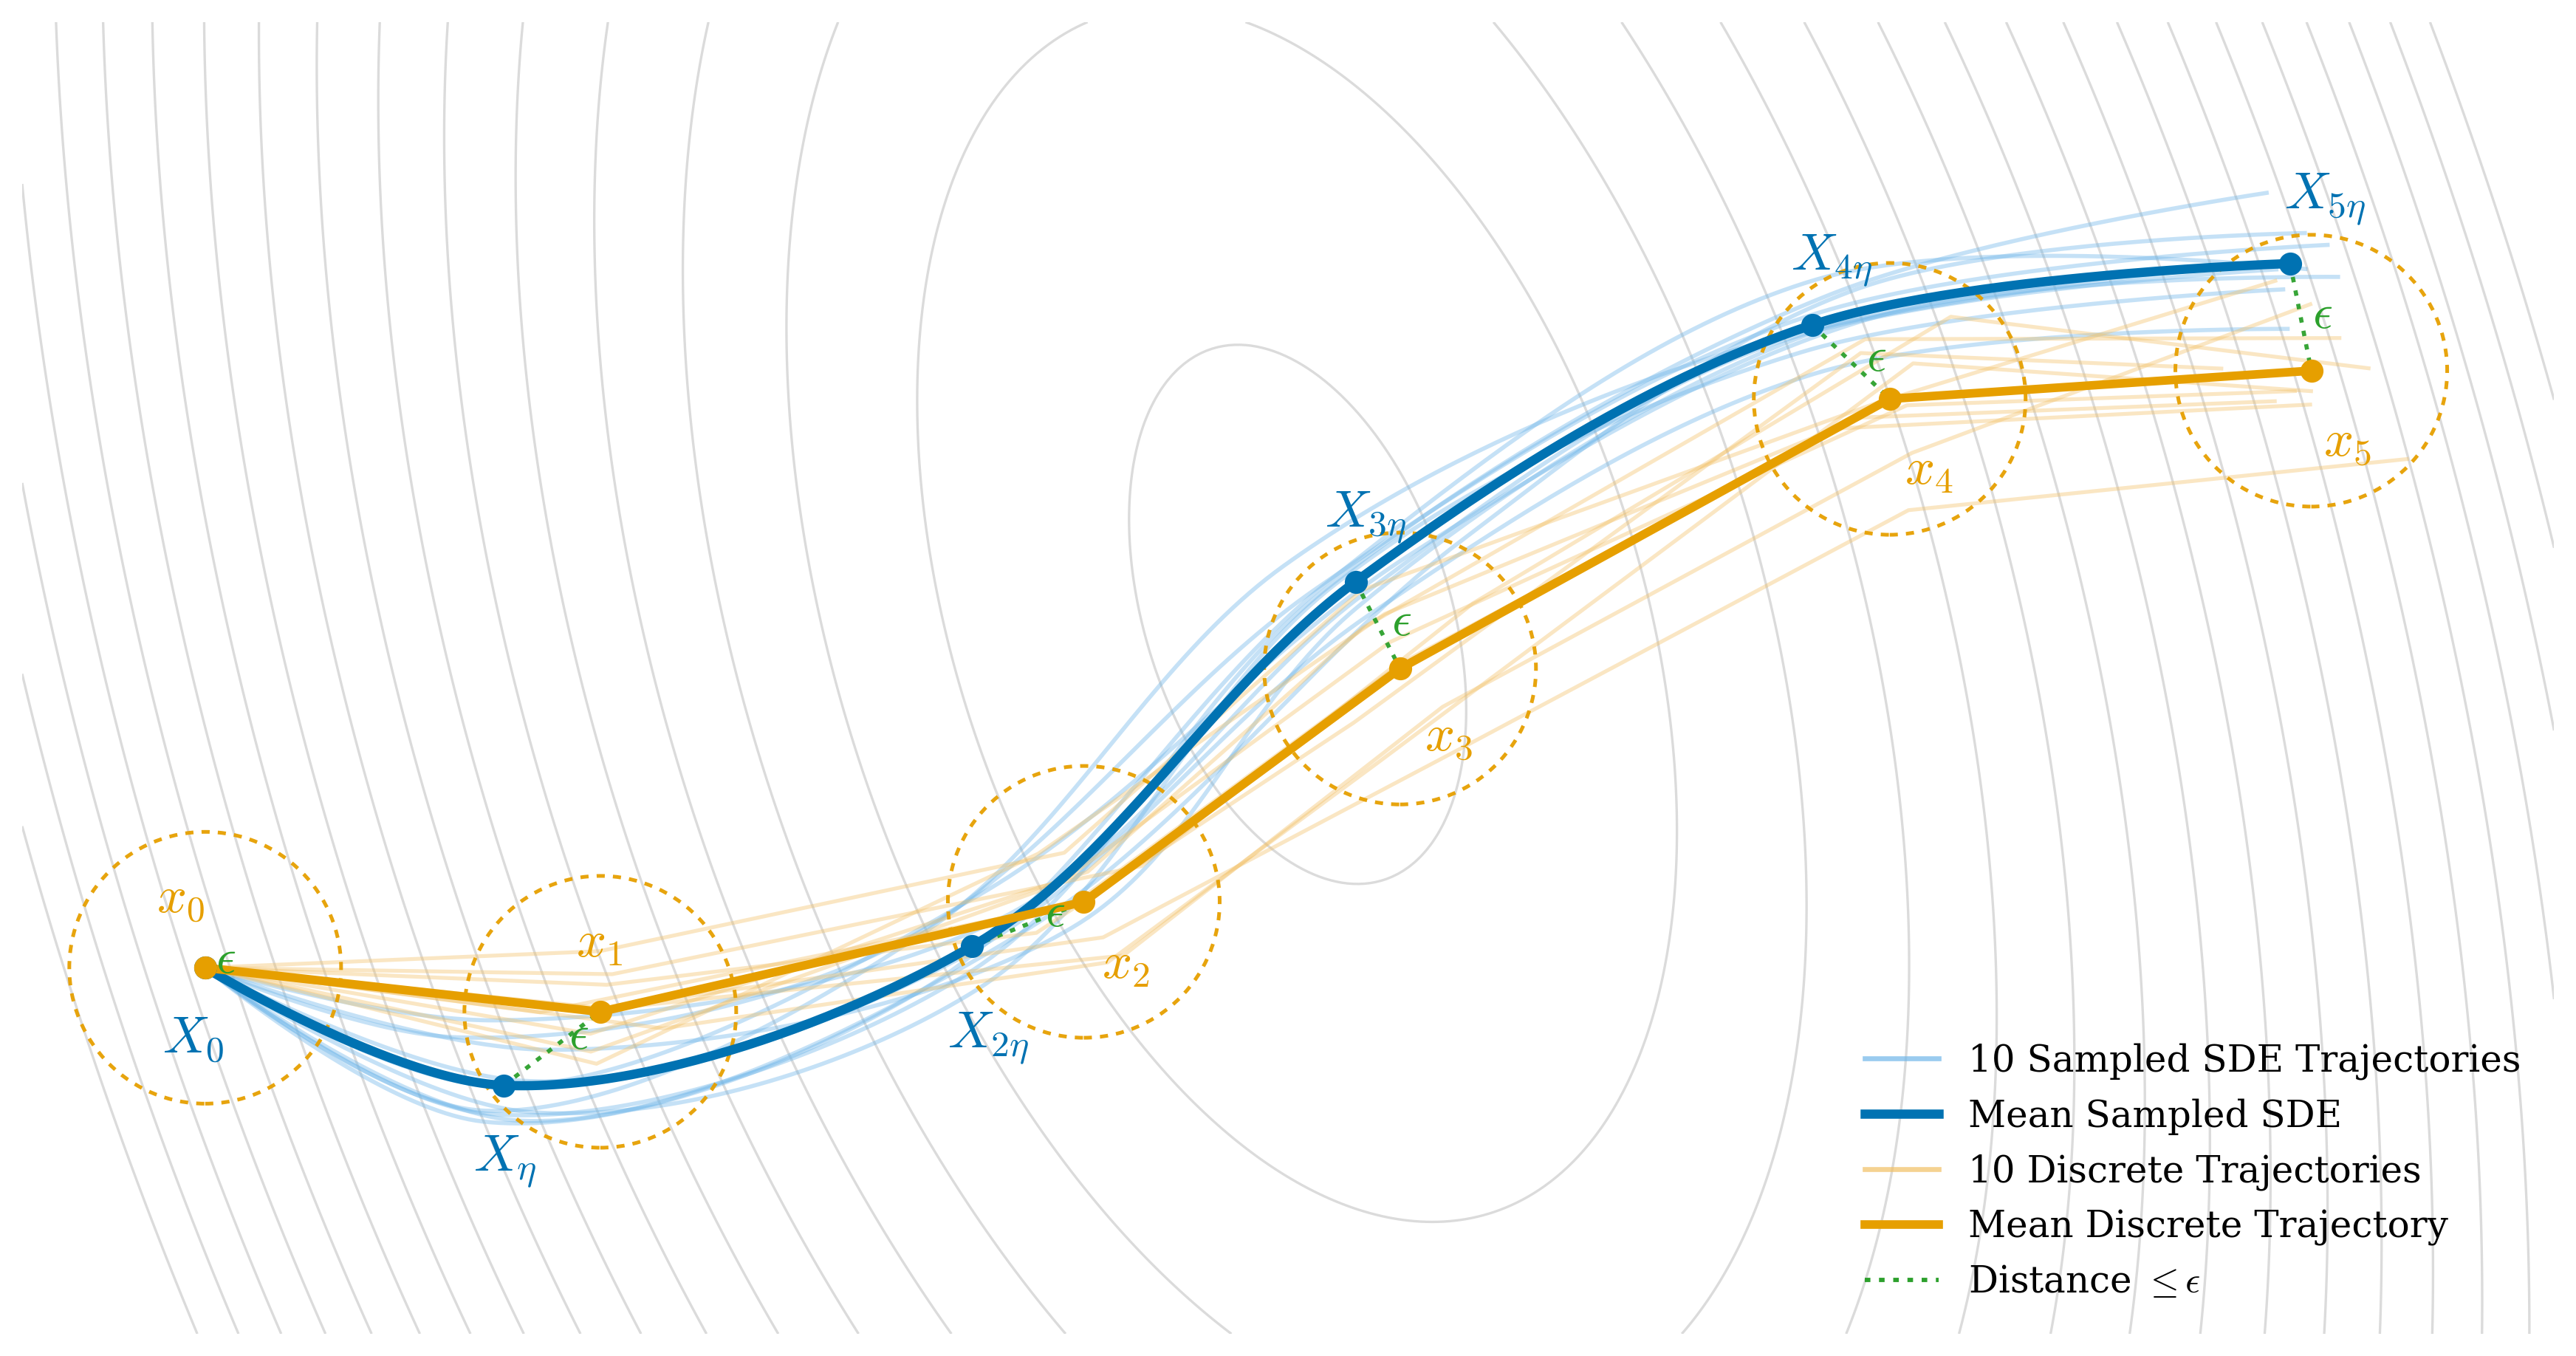

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Circle

# ============================================================
# Utilities
# ============================================================

def catmull_rom_chain(P, samples_per_seg=50, alpha=0.5):
    P = np.asarray(P, dtype=float)
    P_ext = np.vstack([P[0], P, P[-1]])

    curve = []
    for i in range(1, len(P_ext) - 2):
        p0, p1, p2, p3 = P_ext[i - 1], P_ext[i], P_ext[i + 1], P_ext[i + 2]

        def tj(ti, pi, pj):
            return ti + np.linalg.norm(pj - pi) ** alpha

        t0 = 0.0
        t1 = tj(t0, p0, p1)
        t2 = tj(t1, p1, p2)
        t3 = tj(t2, p2, p3)

        if t1 == t0:
            t1 = t0 + 1e-8
        if t2 == t1:
            t2 = t1 + 1e-8
        if t3 == t2:
            t3 = t2 + 1e-8

        ts = np.linspace(t1, t2, samples_per_seg, endpoint=False)

        for t in ts:
            A1 = (t1 - t)/(t1 - t0)*p0 + (t - t0)/(t1 - t0)*p1
            A2 = (t2 - t)/(t2 - t1)*p1 + (t - t1)/(t2 - t1)*p2
            A3 = (t3 - t)/(t3 - t2)*p2 + (t - t2)/(t3 - t2)*p3

            B1 = (t2 - t)/(t2 - t0)*A1 + (t - t0)/(t2 - t0)*A2
            B2 = (t3 - t)/(t3 - t1)*A2 + (t - t1)/(t3 - t1)*A3

            C = (t2 - t)/(t2 - t1)*B1 + (t - t1)/(t2 - t1)*B2
            curve.append(C)

    curve.append(P[-1])
    return np.asarray(curve)


def correlated_noise(n, scale=0.12, rho=0.55, seed=None):
    rng = np.random.default_rng(seed)
    noise = np.zeros((n, 2))
    noise[0] = np.array([0.0, 0.0])
    for k in range(1, n):
        noise[k] = rho * noise[k - 1] + rng.normal(scale=scale, size=2)
    return noise


# ============================================================
# Style
# ============================================================

plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "cm",
    "font.size": 13
})

blue        = "#0072B2"
orange      = "#E69F00"
light_blue  = "#6FB6E9"
light_orange= "#F2BF63"
green       = "#2CA02C"
gray_contour= "0.86"

# ============================================================
# Mean trajectories
# ============================================================

start = np.array([0.25, 0.00])

sde_mean_pts = np.array([
    start,
    [1.20, -0.40],
    [2.75,  0.05],
    [4.05,  1.25],
    [5.55,  2.10],
    [7.10,  2.30],
])

disc_mean_pts = np.array([
    start,
    [1.55, -0.12],
    [3.10,  0.35],
    [4.18,  1.10],
    [5.80,  1.95],
    [7.25,  2.02],
])

# ============================================================
# Generate ensembles
# ============================================================

n_traj = 10
n_pts  = len(sde_mean_pts)

sde_paths_pts  = []
disc_paths_pts = []

rng = np.random.default_rng(7)

for i in range(n_traj):
    noise_sde = correlated_noise(n_pts, scale=0.14, rho=0.62, seed=rng.integers(1_000_000))
    taper = np.linspace(0.65, 1.0, n_pts)
    taper = np.minimum(taper, taper[::-1])
    taper[0] = 0.0
    sde_paths_pts.append(sde_mean_pts + noise_sde * taper[:, None])

    noise_disc = correlated_noise(n_pts, scale=0.18, rho=0.40, seed=rng.integers(1_000_000))
    taper = np.linspace(0.65, 1.0, n_pts)
    taper = np.minimum(taper, taper[::-1])
    taper[0] = 0.0
    disc_paths_pts.append(disc_mean_pts + noise_disc * taper[:, None])

sde_paths_pts  = np.array(sde_paths_pts)
disc_paths_pts = np.array(disc_paths_pts)

sde_emp_mean  = sde_paths_pts.mean(axis=0)
disc_emp_mean = disc_paths_pts.mean(axis=0)

sde_emp_curve = catmull_rom_chain(sde_emp_mean, samples_per_seg=60)
sde_curves    = [catmull_rom_chain(P, samples_per_seg=45) for P in sde_paths_pts]

pairwise_dist = np.linalg.norm(sde_emp_mean - disc_emp_mean, axis=1)
eps = 1.12 * pairwise_dist.max()

# ============================================================
# Background contour plot
# ============================================================

fig, ax = plt.subplots(figsize=(11.5, 6.5), dpi=300)

xx = np.linspace(-0.35, 7.95, 450)
yy = np.linspace(-1.20, 3.10, 350)
X, Y = np.meshgrid(xx, yy)

theta = np.deg2rad(-18)
U = (X - 3.8) * np.cos(theta) - (Y - 1.15) * np.sin(theta)
V = (X - 3.8) * np.sin(theta) + (Y - 1.15) * np.cos(theta)

Z = 0.095 * U**2 + 0.028 * V**2 + 0.010*np.sin(0.65*X + 0.20*Y)
levels = np.linspace(np.percentile(Z, 4), np.percentile(Z, 98), 18)

ax.contour(X, Y, Z, levels=levels, colors=gray_contour, linewidths=0.8, zorder=0)

# ============================================================
# Epsilon balls and connectors
# ============================================================

for p in disc_emp_mean:
    ax.add_patch(Circle(
        p, eps,
        fill=False, edgecolor=orange, linewidth=1.2,
        linestyle=(0, (2.2, 2.2)), alpha=0.95, zorder=2
    ))

for xb, xo in zip(sde_emp_mean, disc_emp_mean):
    ax.plot(
        [xb[0], xo[0]], [xb[1], xo[1]],
        color=green, linewidth=1.35,
        linestyle=(0, (1.3, 2.0)), alpha=0.95, zorder=3
    )
    mid = 0.56 * xo + 0.44 * xb
    ax.text(
        mid[0] + 0.035, mid[1] + 0.03,
        r"$\epsilon$",
        color=green, fontsize=16,
        ha="left", va="center", zorder=6
    )

# ============================================================
# Plot many light trajectories
# ============================================================

for curve in sde_curves:
    ax.plot(curve[:, 0], curve[:, 1], color=light_blue, linewidth=1.35, alpha=0.40, zorder=1)

for P in disc_paths_pts:
    ax.plot(P[:, 0], P[:, 1], color=light_orange, linewidth=1.25, alpha=0.38, zorder=1)

# ============================================================
# Plot empirical means
# ============================================================

ax.plot(sde_emp_curve[:, 0], sde_emp_curve[:, 1], color=blue, linewidth=3.0, zorder=4)
ax.scatter(sde_emp_mean[:, 0], sde_emp_mean[:, 1], s=42, color=blue, zorder=5)

ax.plot(disc_emp_mean[:, 0], disc_emp_mean[:, 1], color=orange, linewidth=2.8, zorder=4)
ax.scatter(disc_emp_mean[:, 0], disc_emp_mean[:, 1], s=42, color=orange, zorder=5)

# ============================================================
# Labels  —  X_0, X_eta, X_{2eta}, ...
# ============================================================

blue_offsets = np.array([
    [-0.14, -0.28],
    [-0.10, -0.28],
    [-0.08, -0.33],
    [-0.10,  0.18],
    [-0.07,  0.18],
    [-0.02,  0.18],
])

orange_offsets = np.array([
    [-0.16,  0.18],
    [-0.08,  0.18],
    [ 0.06, -0.25],
    [ 0.08, -0.27],
    [ 0.05, -0.28],
    [ 0.04, -0.28],
])

for k, p in enumerate(sde_emp_mean):
    if k == 0:
        label = r"$X_0$"
    elif k == 1:
        label = r"$X_{\eta}$"
    else:
        label = rf"$X_{{{k}\eta}}$"
    ax.text(
        p[0] + blue_offsets[k, 0],
        p[1] + blue_offsets[k, 1],
        label,
        color=blue, fontsize=17, zorder=6
    )

for k, p in enumerate(disc_emp_mean):
    ax.text(
        p[0] + orange_offsets[k, 0],
        p[1] + orange_offsets[k, 1],
        rf"$x_{k}$",
        color=orange, fontsize=17, zorder=6
    )

# ============================================================
# Legend
# ============================================================

legend_elements = [
    Line2D([0], [0], color=light_blue,   lw=1.6, alpha=0.7, label="10 Sampled SDE Trajectories"),
    Line2D([0], [0], color=blue,          lw=3.0,            label="Mean Sampled SDE"),
    Line2D([0], [0], color=light_orange,  lw=1.6, alpha=0.7, label="10 Discrete Trajectories"),
    Line2D([0], [0], color=orange,        lw=2.8,            label="Mean Discrete Trajectory"),
    Line2D([0], [0], color=green,         lw=1.4, linestyle=(0, (1.3, 2.0)), label=r"Distance $\leq \epsilon$"),
]

ax.legend(handles=legend_elements, loc="lower right", frameon=False, fontsize=12)

# ============================================================
# Final layout
# ============================================================

ax.set_xlim(-0.35, 7.95)
ax.set_ylim(-1.20, 3.10)
ax.set_aspect("equal", adjustable="box")
ax.axis("off")

fig.tight_layout(pad=0.2)

out_base = "fig_sde_vs_discrete_ensemble_shadowing_with_eps"
fig.savefig(out_base + ".pdf", bbox_inches="tight", pad_inches=0.03)
fig.savefig(out_base + ".png", dpi=300, bbox_inches="tight", pad_inches=0.03)

plt.show()

Diagnostics for the 10 true SGD runs
seed | final point        | min dist. to sharp | outcome
-----|--------------------|--------------------|---------
 101 | [ 1.66, -0.25] |  0.012              | flat
 102 | [ 1.66, -0.25] |  0.002              | flat
 103 | [-1.34, -0.98] |  0.007              | sharp
 107 | [-1.51, -1.00] |  0.008              | sharp
 100 | [ 1.66, -0.25] |  0.047              | flat
 106 | [ 1.66, -0.25] |  0.054              | flat
 108 | [ 1.66, -0.25] |  0.051              | flat
 109 | [ 1.66, -0.25] |  0.009              | flat
 112 | [ 1.66, -0.25] |  0.012              | flat
 114 | [ 1.66, -0.25] |  0.019              | flat



Saved: fig_true_sgd_vs_gd_overlay_clean.pdf / .png / .svg


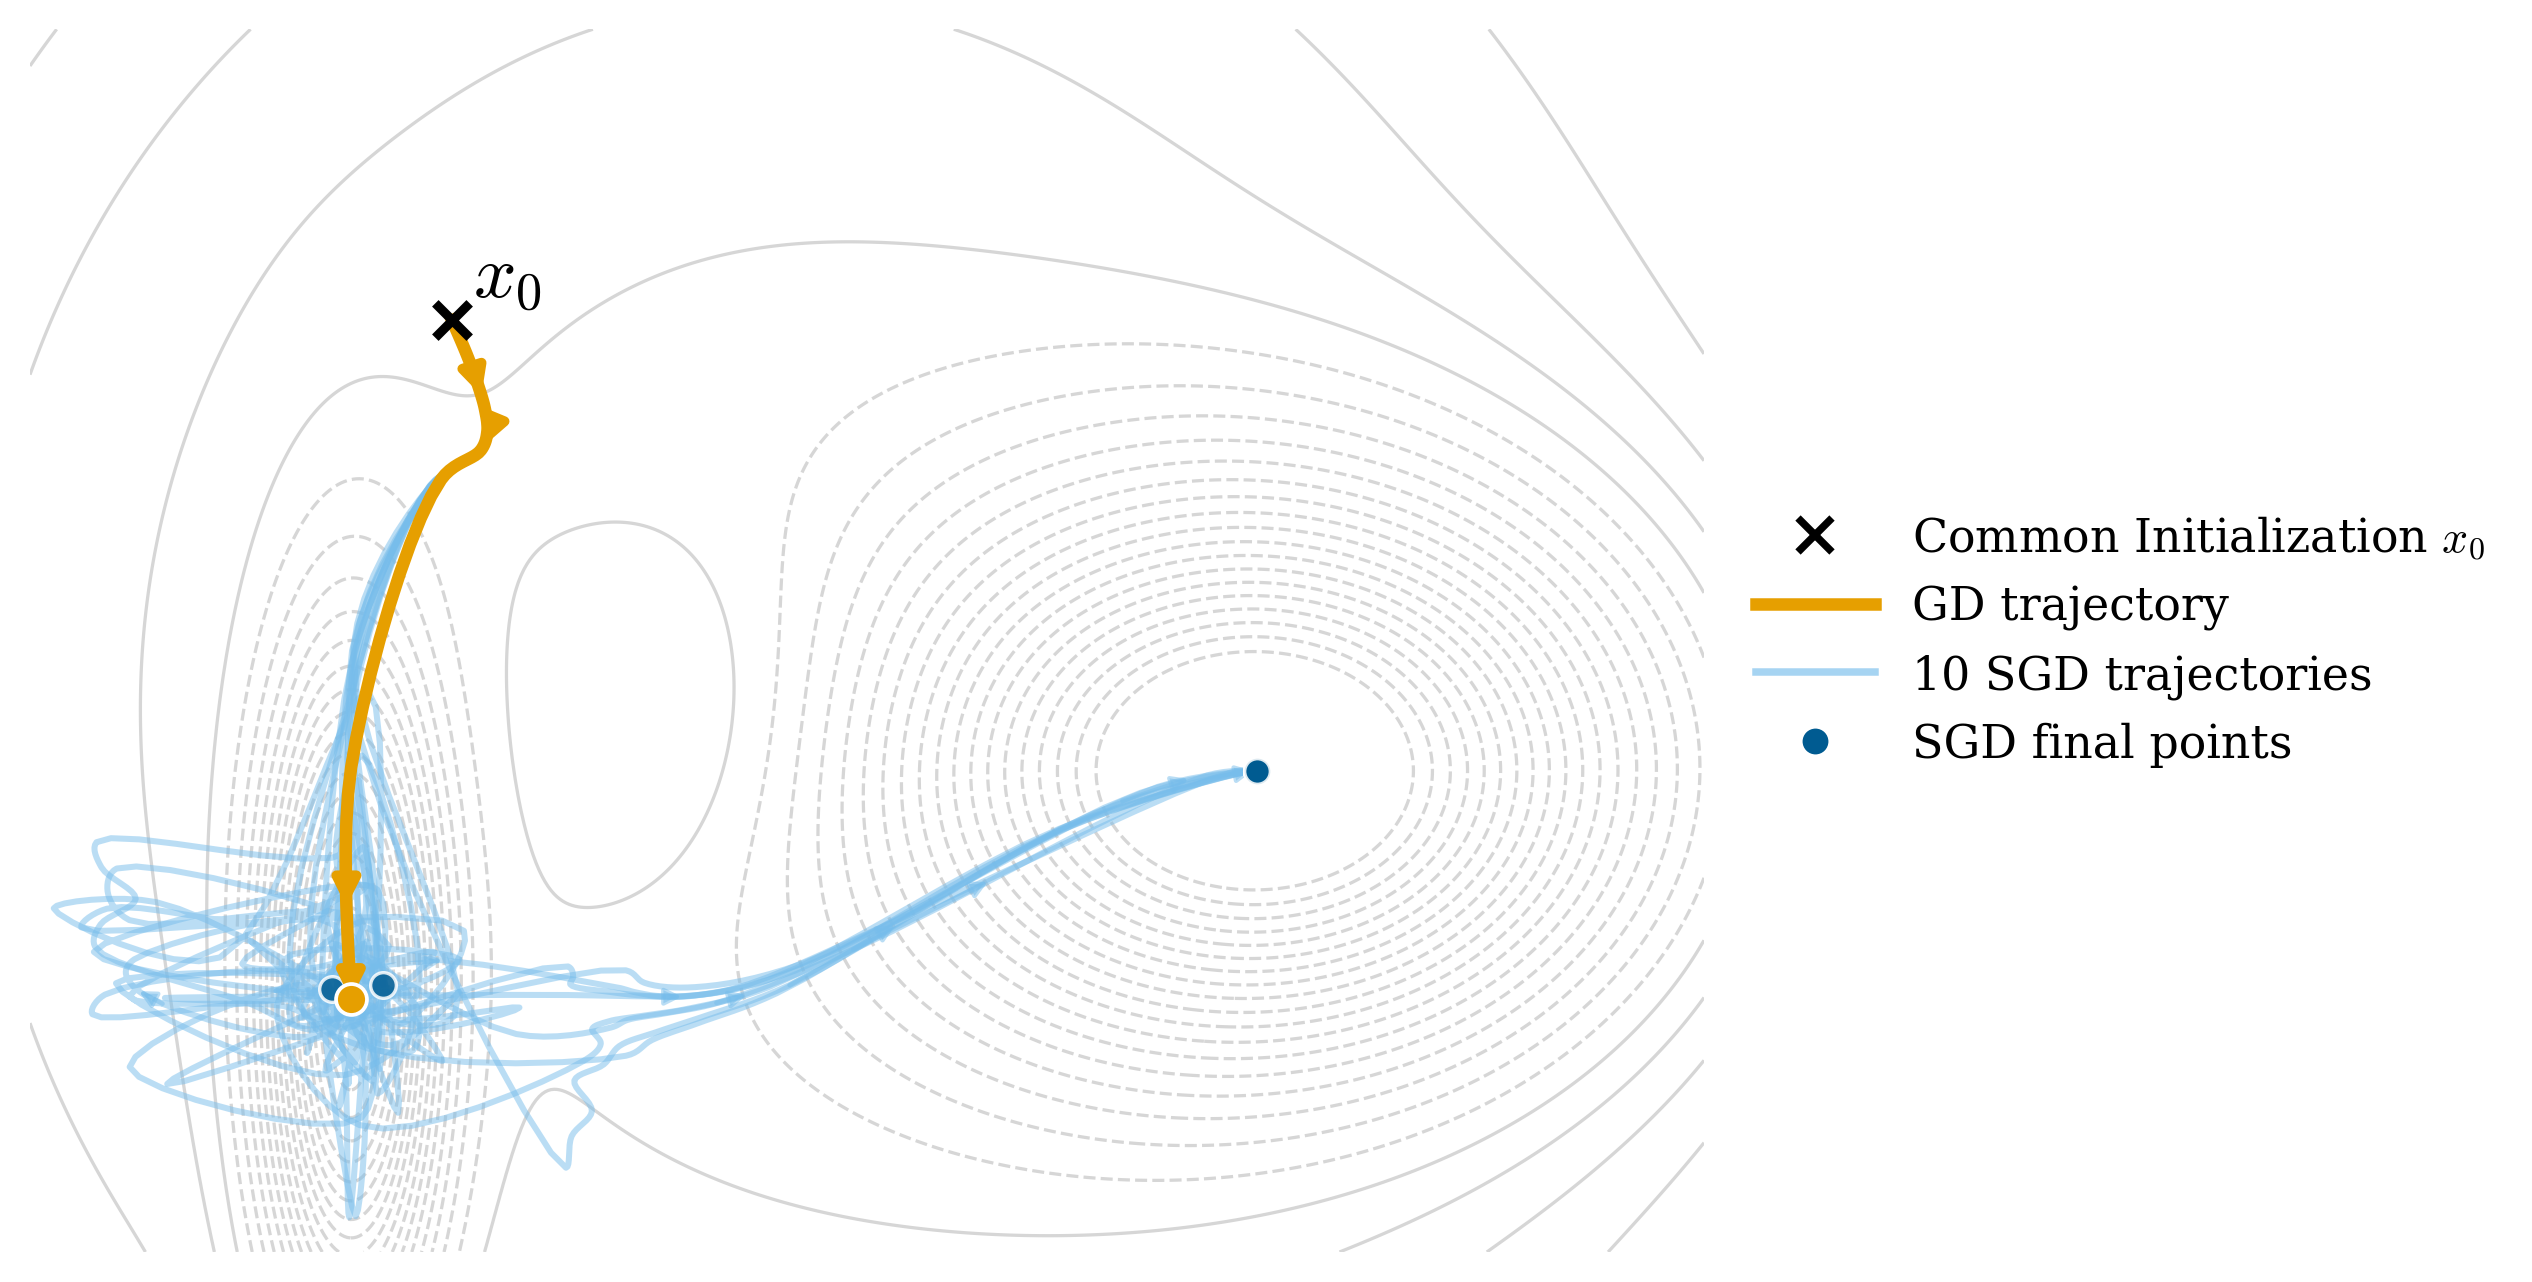

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrowPatch


# =============================================================================
# Global configuration
# =============================================================================

BASENAME = "fig_true_sgd_vs_gd_overlay_clean"

SEED_COMPONENTS = 1
ETA = 0.05
STEPS = 1500
BATCH_SIZE = 1
N_COMPONENTS = 200
NOISE_SIGMA = 1.5

X0 = np.array([-1.10, 1.30])

SGD_SEEDS = [101, 102, 103, 107, 100, 106, 108, 109, 112, 114]


# =============================================================================
# Plot style
# =============================================================================

plt.rcParams.update(
    {
        "font.family": "serif",
        "mathtext.fontset": "cm",
        "font.size": 12,
        "legend.fontsize": 11,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }
)

COLORS = {
    "gd": "#E69F00",
    "sgd_light": "#77BDEB",
    "sgd_mean": "#005B91",
    "contour": "0.84",
    "start": "black",
}


# =============================================================================
# Utility functions
# =============================================================================

def downsample_path(path, n=60):
    path = np.asarray(path)
    idx = np.unique(np.linspace(0, len(path) - 1, n).astype(int))
    return path[idx]


def catmull_rom_chain(points, samples_per_seg=12, alpha=0.5):
    P = np.asarray(points, dtype=float)
    if len(P) < 4:
        return P
    keep = np.r_[True, np.linalg.norm(np.diff(P, axis=0), axis=1) > 1e-10]
    P = P[keep]
    if len(P) < 4:
        return P
    P_ext = np.vstack([P[0], P, P[-1]])
    curve = []
    for i in range(1, len(P_ext) - 2):
        p0, p1, p2, p3 = P_ext[i - 1], P_ext[i], P_ext[i + 1], P_ext[i + 2]
        def tj(ti, pi, pj):
            return ti + np.linalg.norm(pj - pi) ** alpha
        t0 = 0.0
        t1 = tj(t0, p0, p1)
        t2 = tj(t1, p1, p2)
        t3 = tj(t2, p2, p3)
        eps = 1e-12
        if t1 <= t0 + eps: t1 = t0 + eps
        if t2 <= t1 + eps: t2 = t1 + eps
        if t3 <= t2 + eps: t3 = t2 + eps
        ts = np.linspace(t1, t2, samples_per_seg, endpoint=False)
        for t in ts:
            A1 = (t1 - t) / (t1 - t0) * p0 + (t - t0) / (t1 - t0) * p1
            A2 = (t2 - t) / (t2 - t1) * p1 + (t - t1) / (t2 - t1) * p2
            A3 = (t3 - t) / (t3 - t2) * p2 + (t - t2) / (t3 - t2) * p3
            B1 = (t2 - t) / (t2 - t0) * A1 + (t - t0) / (t2 - t0) * A2
            B2 = (t3 - t) / (t3 - t1) * A2 + (t - t1) / (t3 - t1) * A3
            C = (t2 - t) / (t2 - t1) * B1 + (t - t1) / (t2 - t1) * B2
            curve.append(C)
    curve.append(P[-1])
    return np.asarray(curve)


def add_arrow_on_curve(ax, curve, frac, color, lw=2.0, mutation_scale=10, alpha=1.0, zorder=10):
    curve = np.asarray(curve)
    if len(curve) < 5:
        return
    i = int(np.clip(frac * len(curve), 2, len(curve) - 4))
    p0 = curve[i]
    p1 = curve[i + 3]
    arrow = FancyArrowPatch(
        p0, p1,
        arrowstyle="-|>",
        mutation_scale=mutation_scale,
        linewidth=lw,
        color=color,
        alpha=alpha,
        shrinkA=0, shrinkB=0,
        zorder=zorder,
        capstyle="round", joinstyle="round",
    )
    ax.add_patch(arrow)


# =============================================================================
# Finite-sum toy objective
# =============================================================================

SHARP_CENTER = np.array([-1.45, -1.05])
FLAT_CENTER  = np.array([ 1.66, -0.25])


def base_loss_and_grad(x):
    X, Y = float(x[0]), float(x[1])
    value = 0.035 * (0.80 * X**2 + 0.65 * Y**2)
    grad  = np.array([0.035 * 1.60 * X, 0.035 * 1.30 * Y], dtype=float)
    gaussian_terms = [
        (-1.50, -1.45, -1.05, 0.080, 1.20),
        (-1.80,  1.70, -0.25, 1.450, 0.80),
        ( 0.22, -0.15, -0.10, 0.450, 0.50),
    ]
    for A, cx, cy, dx, dy in gaussian_terms:
        Q  = ((X - cx) ** 2) / dx + ((Y - cy) ** 2) / dy
        E  = np.exp(-Q)
        value += A * E
        grad  += A * E * np.array([-2.0 * (X - cx) / dx, -2.0 * (Y - cy) / dy], dtype=float)
    return value, grad


def full_objective_grid(X, Y):
    Z = 0.035 * (0.80 * X**2 + 0.65 * Y**2)
    gaussian_terms = [
        (-1.50, -1.45, -1.05, 0.080, 1.20),
        (-1.80,  1.70, -0.25, 1.450, 0.80),
        ( 0.22, -0.15, -0.10, 0.450, 0.50),
    ]
    for A, cx, cy, dx, dy in gaussian_terms:
        Q  = ((X - cx) ** 2) / dx + ((Y - cy) ** 2) / dy
        Z += A * np.exp(-Q)
    return Z


def noise_envelope_and_grad(x):
    X, Y   = float(x[0]), float(x[1])
    cx, cy = -1.45, -0.95
    dx, dy = 0.20,  0.40
    Q      = ((X - cx) ** 2) / dx + ((Y - cy) ** 2) / dy
    S      = np.exp(-Q)
    gradS  = S * np.array([-2.0 * (X - cx) / dx, -2.0 * (Y - cy) / dy], dtype=float)
    return S, gradS


def make_finite_sum_coefficients(N=N_COMPONENTS, sigma=NOISE_SIGMA, seed=SEED_COMPONENTS):
    rng = np.random.default_rng(seed)
    A   = rng.normal(size=(N, 2))
    A  -= A.mean(axis=0, keepdims=True)
    A  /= A.std(axis=0, keepdims=True)
    A  *= sigma
    return A


def component_loss_and_grad(x, a_i):
    F, gradF = base_loss_and_grad(x)
    S, gradS = noise_envelope_and_grad(x)
    ax       = float(np.dot(a_i, x))
    fi       = F + ax * S
    gi       = gradF + a_i * S + ax * gradS
    return fi, gi


# =============================================================================
# Optimizers
# =============================================================================

def run_gd(x0, eta=ETA, steps=STEPS):
    x    = np.asarray(x0, dtype=float).copy()
    path = [x.copy()]
    for _ in range(steps):
        _, grad = base_loss_and_grad(x)
        x = x - eta * grad
        path.append(x.copy())
    return np.asarray(path)


def run_sgd(x0, A, eta=ETA, batch_size=BATCH_SIZE, steps=STEPS, seed=0):
    rng  = np.random.default_rng(seed)
    x    = np.asarray(x0, dtype=float).copy()
    path = [x.copy()]
    N    = len(A)
    for _ in range(steps):
        idx  = rng.integers(0, N, size=batch_size)
        grad = np.zeros(2)
        for j in idx:
            _, grad_j = component_loss_and_grad(x, A[j])
            grad += grad_j
        grad /= batch_size
        x = x - eta * grad
        path.append(x.copy())
    return np.asarray(path)


# =============================================================================
# Main figure
# =============================================================================

def make_overlay_figure(basename=BASENAME, show_diagnostics=True):
    # -------------------------------------------------------------------------
    # Simulate GD and SGD
    # -------------------------------------------------------------------------
    A         = make_finite_sum_coefficients()
    gd_path   = run_gd(X0)
    sgd_paths = [run_sgd(X0, A, seed=seed) for seed in SGD_SEEDS]

    if show_diagnostics:
        print("Diagnostics for the 10 true SGD runs")
        print("seed | final point        | min dist. to sharp | outcome")
        print("-----|--------------------|--------------------|---------")
        for seed, path in zip(SGD_SEEDS, sgd_paths):
            final           = path[-1]
            min_dist_sharp  = np.min(np.linalg.norm(path - SHARP_CENTER, axis=1))
            outcome         = "flat" if final[0] > 0.8 else "sharp"
            print(f"{seed:4d} | [{final[0]: .2f}, {final[1]: .2f}] | {min_dist_sharp: .3f}              | {outcome}")

    # -------------------------------------------------------------------------
    # Landscape contours
    # -------------------------------------------------------------------------
    xx = np.linspace(-2.55, 3.20, 560)
    yy = np.linspace(-1.90, 2.30, 430)
    X, Y = np.meshgrid(xx, yy)
    Z    = full_objective_grid(X, Y)
    levels = np.linspace(np.percentile(Z, 3.0), np.percentile(Z, 98.0), 22)

    fig, ax = plt.subplots(figsize=(7.2, 6.2), dpi=300)
    ax.contour(X, Y, Z, levels=levels, colors=COLORS["contour"], linewidths=0.78, zorder=0)

    # -------------------------------------------------------------------------
    # Plot SGD sample paths + final points
    # -------------------------------------------------------------------------
    for path in sgd_paths:
        smooth_path = catmull_rom_chain(downsample_path(path, n=55), samples_per_seg=8)
        ax.plot(
            smooth_path[:, 0], smooth_path[:, 1],
            color=COLORS["sgd_light"], linewidth=1.45, alpha=0.50, zorder=4,
        )
        add_arrow_on_curve(
            ax, smooth_path, frac=0.72,
            color=COLORS["sgd_light"], lw=1.1, mutation_scale=8, alpha=0.50, zorder=5,
        )
        final = path[-1]
        ax.scatter(
            final[0], final[1],
            marker="o", s=38,
            color=COLORS["sgd_mean"], edgecolors="white", linewidths=0.8,
            zorder=8, alpha=0.85,
        )

    # -------------------------------------------------------------------------
    # Plot GD path
    # -------------------------------------------------------------------------
    gd_smooth_path = catmull_rom_chain(downsample_path(gd_path, n=42), samples_per_seg=10)
    ax.plot(
        gd_smooth_path[:, 0], gd_smooth_path[:, 1],
        color=COLORS["gd"], linewidth=3.0, zorder=20,
    )
    for frac in (0.18, 0.38, 0.60, 0.80):
        add_arrow_on_curve(ax, gd_smooth_path, frac=frac, color=COLORS["gd"], lw=2.4, mutation_scale=12, zorder=22)

    gd_final = gd_path[-1]
    ax.scatter(
        gd_final[0], gd_final[1],
        marker="o", s=55,
        color=COLORS["gd"], edgecolors="white", linewidths=0.9, zorder=24,
    )

    # -------------------------------------------------------------------------
    # Common initialization
    # -------------------------------------------------------------------------
    ax.scatter(X0[0], X0[1], marker="x", s=68, color=COLORS["start"], linewidths=2.2, zorder=30)
    ax.text(X0[0] + 0.07, X0[1] + 0.08, r"$x_0$", fontsize=18, color=COLORS["start"], zorder=31)

    # -------------------------------------------------------------------------
    # Layout
    # -------------------------------------------------------------------------
    ax.set_xlim(-2.55, 3.20)
    ax.set_ylim(-1.90, 2.30)
    ax.set_aspect("equal", adjustable="box")
    ax.axis("off")

    # -------------------------------------------------------------------------
    # Legend
    # -------------------------------------------------------------------------
    legend_handles = [
        Line2D([0], [0], marker="x", color="black", lw=0, markersize=8, markeredgewidth=1.8, label=r"Common Initialization $x_0$"),
        Line2D([0], [0], color=COLORS["gd"],        lw=3.0,              label="GD trajectory"),
        Line2D([0], [0], color=COLORS["sgd_light"], lw=1.8, alpha=0.65,  label="10 SGD trajectories"),
        Line2D([0], [0], marker="o", color=COLORS["sgd_mean"], lw=0, markersize=7,
               markeredgecolor="white", markeredgewidth=0.8,             label="SGD final points"),
    ]
    leg = ax.legend(
        handles=legend_handles,
        loc="center left",
        frameon=False,
        bbox_to_anchor=(1.02, 0.5),
        handlelength=2.6,
        borderaxespad=0.0,
    )

    # -------------------------------------------------------------------------
    # Save — same convention as fig_sde_vs_discrete (working directory, no Path)
    # -------------------------------------------------------------------------
    fig.savefig(basename + ".pdf", bbox_inches="tight", bbox_extra_artists=[leg], pad_inches=0.04)
    fig.savefig(basename + ".png", dpi=300, bbox_inches="tight", bbox_extra_artists=[leg], pad_inches=0.04)
    fig.savefig(basename + ".svg", bbox_inches="tight", bbox_extra_artists=[leg], pad_inches=0.04)

    print(f"\nSaved: {basename}.pdf / .png / .svg")


make_overlay_figure(basename=BASENAME, show_diagnostics=True)